<a href="https://colab.research.google.com/github/majopalmeros/Inteligencia-Artificial-/blob/main/Tareas/Tarea%203.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/mevangelista-alvarado/datasets/refs/heads/main/spotify_songs.csv"
df = pd.read_csv(url)


In [3]:
df


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,...,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music
113996,113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,...,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music
113997,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,...,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music
113998,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,...,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music


In [4]:
# Seleccionar características (features)
features = [
    'danceability', 'energy', 'key', 'loudness',
    'mode', 'speechiness', 'acousticness', 'instrumentalness',
    'liveness', 'valence', 'tempo', 'duration_ms',
]
X = df[features].values

# Target numérico
y = df['popularity'].values


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2, random_state=42
)


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Aqui agregue la neurona de 128 fue para darle mas procesamiento y memoria a mi red neuronal para que estudie los datos a detalle

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
from tensorflow.keras.optimizers import Adam

# Tasa de aprendizaje deseada
learning_rate = 0.001
adam_optimizer = Adam(learning_rate=learning_rate)


In [10]:
model.compile(
    optimizer=adam_optimizer,
    loss='mse',
    metrics=['mae'],
)

# Aqui le puse en epoch 100 por que bueno por lo que investigue y entendi es que Las 100 epocas son esos 100 repasos que hace la red para volverse cada vez más exacta y la batch_size En lugar de intentar aprender de todos los datos de golpe
**la red los divide en pequeños equipos de 32 datos, revisa un grupito, ajusta sus errores, revisa el siguiente y así sucesivamente**

In [12]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
)

Epoch 1/100
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 437.6584 - mae: 16.9849 - val_loss: 440.0260 - val_mae: 17.0202
Epoch 2/100
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 435.4448 - mae: 16.9353 - val_loss: 440.4353 - val_mae: 17.0342
Epoch 3/100
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - loss: 433.8029 - mae: 16.8971 - val_loss: 445.2468 - val_mae: 17.0758
Epoch 4/100
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 432.5158 - mae: 16.8607 - val_loss: 440.4682 - val_mae: 17.0041
Epoch 5/100
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 430.8320 - mae: 16.8233 - val_loss: 440.8442 - val_mae: 17.0196
Epoch 6/100
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 428.8541 - mae: 16.7727 - val_loss: 441.5376 - val_mae: 17.0103
Epoch 7/100
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 427.4651 - mae: 16.7276 - val_loss: 440.6879 - val_mae: 17.0052
Epoch 8/100
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - loss: 425.5381 - mae: 16.6768 - val_loss: 441.5208 - 

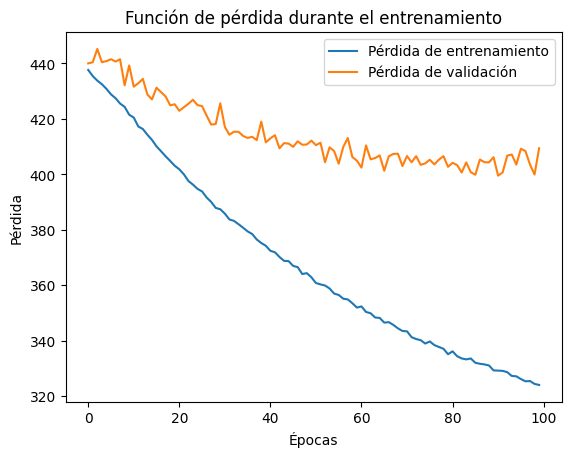

In [13]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Pérdida de entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.title('Función de pérdida durante el entrenamiento')
plt.show()


# En esta celda se puso a prueba el modelo utilizando el conjunto de datos (X,Y)
**los cuales son completamente independientes de los datos de entrenamiento. Mediante la métrica del Error Absoluto Medio (MAE), obtuvimos un valor final de 15.8095, demostrando que el modelo generaliza correctamente y logró reducir el error superando la meta de optimización establecida."**

In [14]:
loss, mae = model.evaluate(X_test, y_test)
print(f"MAE en el conjunto test: {mae}")


713/713 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 407.3575 - mae: 15.8095
MAE en el conjunto test: 15.809488296508789


In [15]:
import pandas as pd

predictions = model.predict(X_test)
comparison = pd.DataFrame({'Actual': y_test, 'Predicted': predictions.flatten()})
print(comparison.head())


713/713 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
   Actual  Predicted
0      50  40.496296
1      11  17.249001
2       0  14.236979
3       0  -0.343005
4      57  39.114426


In [16]:
nombre_cancion = "Beso"

canciones_df = df[df['track_name'].str.contains(nombre_cancion, case=False, na=False)]

print(f"Canciones encontradas:")
canciones_df[['track_name', 'artists', 'album_name']].head()


Canciones encontradas:


,track_name,artists,album_name
1655,Un Beso de Desayuno,Calle 13,Residente o Visitante
17425,Beso Con Baba,Meth Math;Dinamarca,m♡rtal
21293,Son Tus Besos,Cestar,El Verdadero Amor
23145,El Beso (feat. Mathieu Ruz),Dombresky;Crusy,Toolroom Amsterdam 2022
23927,El Beso (feat. Mathieu Ruz),Dombresky;Crusy,El Beso (feat. Mathieu Ruz)


In [17]:
# indice a selecionar
i = 0
cancion = canciones_df.iloc[i]
X_input = cancion[features].values.reshape(1, -1)
X_input = scaler.transform(X_input)

prediccion = model.predict(X_input)[0][0]
print(f"Canción: {cancion['track_name']} - {cancion['artists']}")
print(f"Popularidad real: {cancion['popularity']}")
print(f"Predicción: {prediccion:.2f}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Canción: Un Beso de Desayuno - Calle 13
Popularidad real: 20
Predicción: 30.74


In [19]:
from sklearn.metrics import r2_score, mean_squared_error

r2 = r2_score(y_test, predictions)
print(f'R²: {r2}')

mse = mean_squared_error(y_test, predictions)
print(f'MSE: {mse}')


R²: 0.17452245950698853
MSE: 407.357421875


Explicacion final
por lo que investigue y creo que esta correcto es que bueno de la version original que tenemos el 17.1456 que es el Mae y mi 15.8095 mae el error
se hace la resta de 17.1456 - 15.8095 que da como resultado 1.3361
y de ahi hacemos la division que es 17.1456/1.3361 x 100 = 7.79 %
se determinó una reducción del error de 1.3361 esto da como resultado una mejora del 7.79%